# SHAP analysis of the original Random Forest models

Additional analysis for Reviewer 1, Comment 5. This notebook explains the
saved Random Forest models for HAZ, WAZ and classification. It does not fit
models or change the primary cross-validation results.

The saved models are the 80:20 holdout fits from the original regression
(cells 13/16) and classification (cells 24/27) notebooks, rather than any
individual cross-validation fold. Input features, encoding, row order and
explanation samples follow the original notebooks. No artefacts from
`results/revision_1/supervised` are used.

Run all cells from the repository root. Outputs: `results/shap_revised/`.

In [1]:
import os
os.environ.setdefault('MPLCONFIGDIR', '/tmp/icdees-shap-mpl')

from pathlib import Path
import hashlib
import importlib.metadata
import json
import time

import joblib
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
from IPython.display import display
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

ROOT = Path.cwd()
assert (ROOT / 'Stunting_Regression_Analysis.ipynb').exists(), 'Run from repository root'
OUT = ROOT / 'results/shap_revised'
OUT.mkdir(parents=True, exist_ok=True)
for folder in ['regression', 'classification']:
    (OUT / folder).mkdir(exist_ok=True)

# Preserve the original plotting setup, including the order of the theme call.
mpl.rcParams['figure.dpi'] = 500
mpl.rcParams['font.family'] = 'serif'
mpl.rcParams['font.serif'] = ['Times New Roman'] + mpl.rcParams['font.serif']
sns.set_theme(style='whitegrid')
plt.rcParams['figure.max_open_warning'] = 0

DATA_PATH = Path('dataset/Stunting Wasting Dataset (Synthetic)/stunting_wasting_dataset.csv')
MODEL_PATHS = {
    'HAZ': Path('results/regression/stunting_random_forest_reg_haz.joblib'),
    'WAZ': Path('results/regression/stunting_random_forest_reg_waz.joblib'),
    'classification': Path('results/classification/stunting_random_forest_classifier.joblib'),
}
ORIGINAL_FIGURES = [
    Path('results/regression/regression_shap_summary.png'),
    Path('results/regression/shap_summary_komparasi.png'),
    Path('results/classification/classification_shap_summary.png'),
    Path('results/classification/classification_shap_waterfall.png'),
]
protected_paths = [
    DATA_PATH, *MODEL_PATHS.values(), *ORIGINAL_FIGURES,
    Path('results/classification/stunting_target_encoder.joblib'),
    Path('Stunting_Regression_Analysis.ipynb'),
    Path('Stunting_Classification_Analysis.ipynb'),
]

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

source_hashes = {str(path): sha256(path) for path in protected_paths}
print('Outputs:', OUT.relative_to(ROOT))
print('Original plotting font after seaborn theme:', mpl.rcParams['font.family'])

Outputs: results/shap_revised
Original plotting font after seaborn theme: ['sans-serif']


## Original inputs and explanation samples

The original sex-specific WHO merges retain every input row and are sorted
back to the CSV index. SHAP only needs those input columns, so the frozen
models can be explained without recomputing or changing the WHO targets.

Regression retains the original full-frame sample of 500 rows (seed 42).
Its indices are checked against the original holdout. Classification retains
the original sample of 500 holdout rows (seed 42). These two sample sets differ.

In [2]:
df = pd.read_csv(DATA_PATH).rename(columns={
    'Jenis Kelamin': 'Gender',
    'Umur (bulan)': 'Age (months)',
    'Tinggi Badan (cm)': 'Height (cm)',
    'Berat Badan (kg)': 'Weight (kg)',
})
df['Gender'] = df['Gender'].replace({'Laki-laki': 'Male', 'Perempuan': 'Female'})
gender_encoder = LabelEncoder().fit(df['Gender'])
assert gender_encoder.classes_.tolist() == ['Female', 'Male']
df['Gender_Encoded'] = gender_encoder.transform(df['Gender'])
target_encoder = joblib.load('results/classification/stunting_target_encoder.joblib')
assert target_encoder.classes_.tolist() == ['Normal', 'Severely Stunted', 'Stunted', 'Tall']
y = target_encoder.transform(df['Stunting'])

FEATURES = {
    'HAZ': ['Gender_Encoded', 'Age (months)', 'Height (cm)'],
    'WAZ': ['Gender_Encoded', 'Age (months)', 'Weight (kg)'],
    'classification': ['Gender_Encoded', 'Age (months)', 'Height (cm)', 'Weight (kg)'],
}
assert len(df) == 100000 and df.index.equals(pd.RangeIndex(100000))
assert not df[FEATURES['classification']].isna().any().any()
train_rows, test_rows = train_test_split(df.index.to_numpy(), test_size=0.2, random_state=42)
assert len(train_rows) == 80000 and len(test_rows) == 20000
assert not set(train_rows).intersection(test_rows)

X = {task: df[features].copy() for task, features in FEATURES.items()}
samples = {
    'HAZ': X['HAZ'].sample(500, random_state=42),
    'WAZ': X['WAZ'].sample(500, random_state=42),
    'classification': X['classification'].loc[test_rows].sample(500, random_state=42),
}
for task, sample in samples.items():
    assert sample.index.is_unique and len(sample) == 500
    assert sample.index.isin(test_rows).all(), f'{task}: non-holdout explanation row'
assert samples['HAZ'].index.equals(samples['WAZ'].index)
print('Rows: 100,000; training: 80,000; holdout: 20,000')
print('All three explanation samples are entirely in the original holdout.')
print('Stunted class:', target_encoder.transform(['Stunted'])[0])

Rows: 100,000; training: 80,000; holdout: 20,000
All three explanation samples are entirely in the original holdout.
Stunted class: 2


In [3]:
models = {task: joblib.load(path) for task, path in MODEL_PATHS.items()}
for task, model in models.items():
    assert model.feature_names_in_.tolist() == FEATURES[task]
    assert model.random_state == 42
    assert model.n_estimators == (50 if task == 'classification' else 30)
    assert model._n_samples == len(train_rows)
clf = models['classification']
assert clf.classes_.tolist() == list(range(len(target_encoder.classes_)))
assert clf.class_weight == 'balanced'
stunted_code = int(target_encoder.transform(['Stunted'])[0])
stunted_output = int(np.flatnonzero(clf.classes_ == stunted_code)[0])

# Check the split/encoding against the balanced bootstrap counts in saved trees.
training_y = y[train_rows]
counts = np.bincount(training_y, minlength=len(clf.classes_))
class_weights = len(training_y) / (len(counts) * counts)
root_errors = []
for tree_index in [0, 1, len(clf.estimators_) - 1]:
    boot_y = training_y[clf.estimators_samples_[tree_index]]
    weighted = np.bincount(boot_y, weights=class_weights[boot_y], minlength=len(counts))
    expected = weighted / weighted.sum()
    actual = clf.estimators_[tree_index].tree_.value[0, 0]
    root_errors.append(float(np.max(np.abs(actual - expected))))
    np.testing.assert_allclose(actual, expected, rtol=0, atol=1e-10)
print('Training class counts:', dict(zip(target_encoder.classes_, counts.tolist())))
print('Saved classifier split fingerprint max error:', max(root_errors))

Training class counts: {'Normal': 57906, 'Severely Stunted': 4673, 'Stunted': 12868, 'Tall': 4553}
Saved classifier split fingerprint max error: 1.5382140006181544e-13


## Compute and check TreeSHAP

Use exact, tree-path-dependent TreeSHAP, matching the original no-background
tree explainer. For the regressors, contributions use the predicted Z-score
scale. For the Random Forest classifier, contributions sum to the predicted
class probability. The baseline uses the fitted tree statistics, including
classification training weights; it is not the class prevalence.

In [4]:
explainers, explanations, predictions, max_errors, elapsed = {}, {}, {}, {}, {}
for task, model in models.items():
    started = time.monotonic()
    explainer = shap.TreeExplainer(
        model, feature_perturbation='tree_path_dependent', model_output='raw',
    )
    explanation = explainer(samples[task], approximate=False, check_additivity=True)
    prediction = (model.predict_proba(samples[task]) if task == 'classification'
                  else model.predict(samples[task]))
    reconstructed = explanation.base_values + explanation.values.sum(axis=1)
    np.testing.assert_allclose(reconstructed, prediction, rtol=0, atol=1e-7)
    explainers[task], explanations[task], predictions[task] = explainer, explanation, prediction
    max_errors[task] = float(np.max(np.abs(reconstructed - prediction)))
    elapsed[task] = time.monotonic() - started
    print(f'{task}: {elapsed[task]:.2f} s; max additivity error {max_errors[task]:.3g}')

ranking_rows = []
for task, explanation in explanations.items():
    values = explanation.values[:, :, stunted_output] if task == 'classification' else explanation.values
    for rank, index in enumerate(np.argsort(-np.abs(values).mean(axis=0)), start=1):
        ranking_rows.append({
            'Task': task, 'Output': 'P(Stunted)' if task == 'classification' else task,
            'Rank': rank, 'Feature': FEATURES[task][index],
            'Mean_absolute_SHAP': float(np.abs(values[:, index]).mean()),
            'Minimum_SHAP': float(values[:, index].min()),
            'Maximum_SHAP': float(values[:, index].max()),
        })
importance = pd.DataFrame(ranking_rows)
importance.to_csv(OUT / 'feature_importance.csv', index=False)
display(importance)

HAZ: 17.55 s; max additivity error 1.59e-13
WAZ: 7.87 s; max additivity error 1.16e-13
classification: 9.02 s; max additivity error 1.34e-13


,Task,Output,Rank,Feature,Mean_absolute_SHAP,Minimum_SHAP,Maximum_SHAP
0,HAZ,HAZ,1,Height (cm),1.473699,-4.739474,4.135129
1,HAZ,HAZ,2,Age (months),1.137840,-2.902690,3.727692
2,HAZ,HAZ,3,Gender_Encoded,0.269291,-0.426096,0.347057
3,WAZ,WAZ,1,Weight (kg),1.829939,-7.317587,3.782258
4,WAZ,WAZ,2,Age (months),1.110157,-2.728557,4.514779
5,WAZ,WAZ,3,Gender_Encoded,0.239743,-0.354703,0.335096
6,classification,P(Stunted),1,Height (cm),0.179296,-0.345508,0.413481
7,classification,P(Stunted),2,Age (months),0.123158,-0.187748,0.453994
8,classification,P(Stunted),3,Gender_Encoded,0.039237,-0.222849,0.225875
9,classification,P(Stunted),4,Weight (kg),0.010807,-0.071973,0.088377


## Regression figures

Keep the original panel arrangement, titles, font sizes, white-grid theme,
SHAP colour map and 500 DPI export. Seed the jitter for reproducible rendering.
Save both PNG and PDF; the original image files are preserved.

<ipython-input-1-fb5913276b19>:20: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(explanations['HAZ'], samples['HAZ'], show=False)
<ipython-input-1-fb5913276b19>:27: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(explanations['HAZ'], samples['HAZ'], show=False, plot_size=None)
<ipython-input-1-fb5913276b19>:30: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(explanations['WAZ'], samples['WAZ'], show=False, 

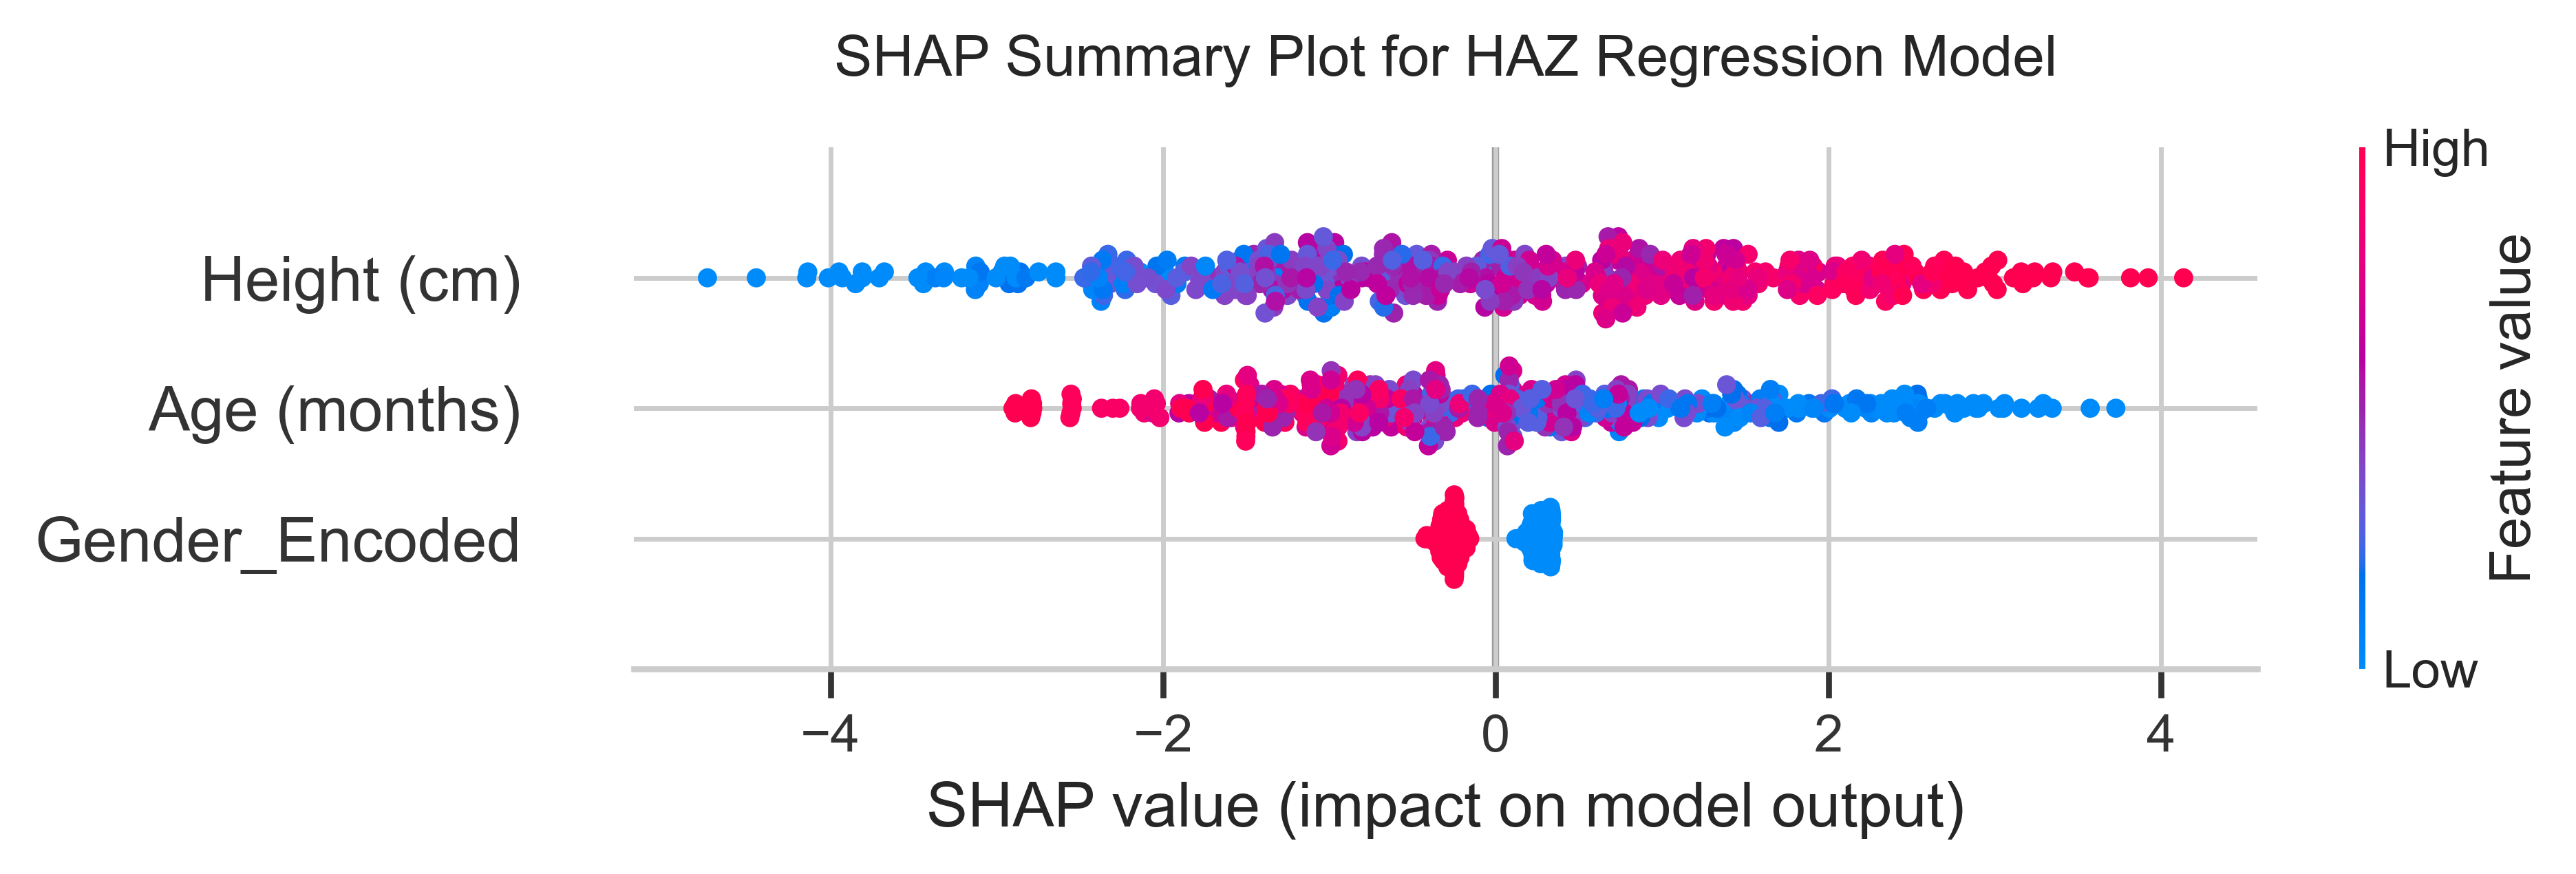

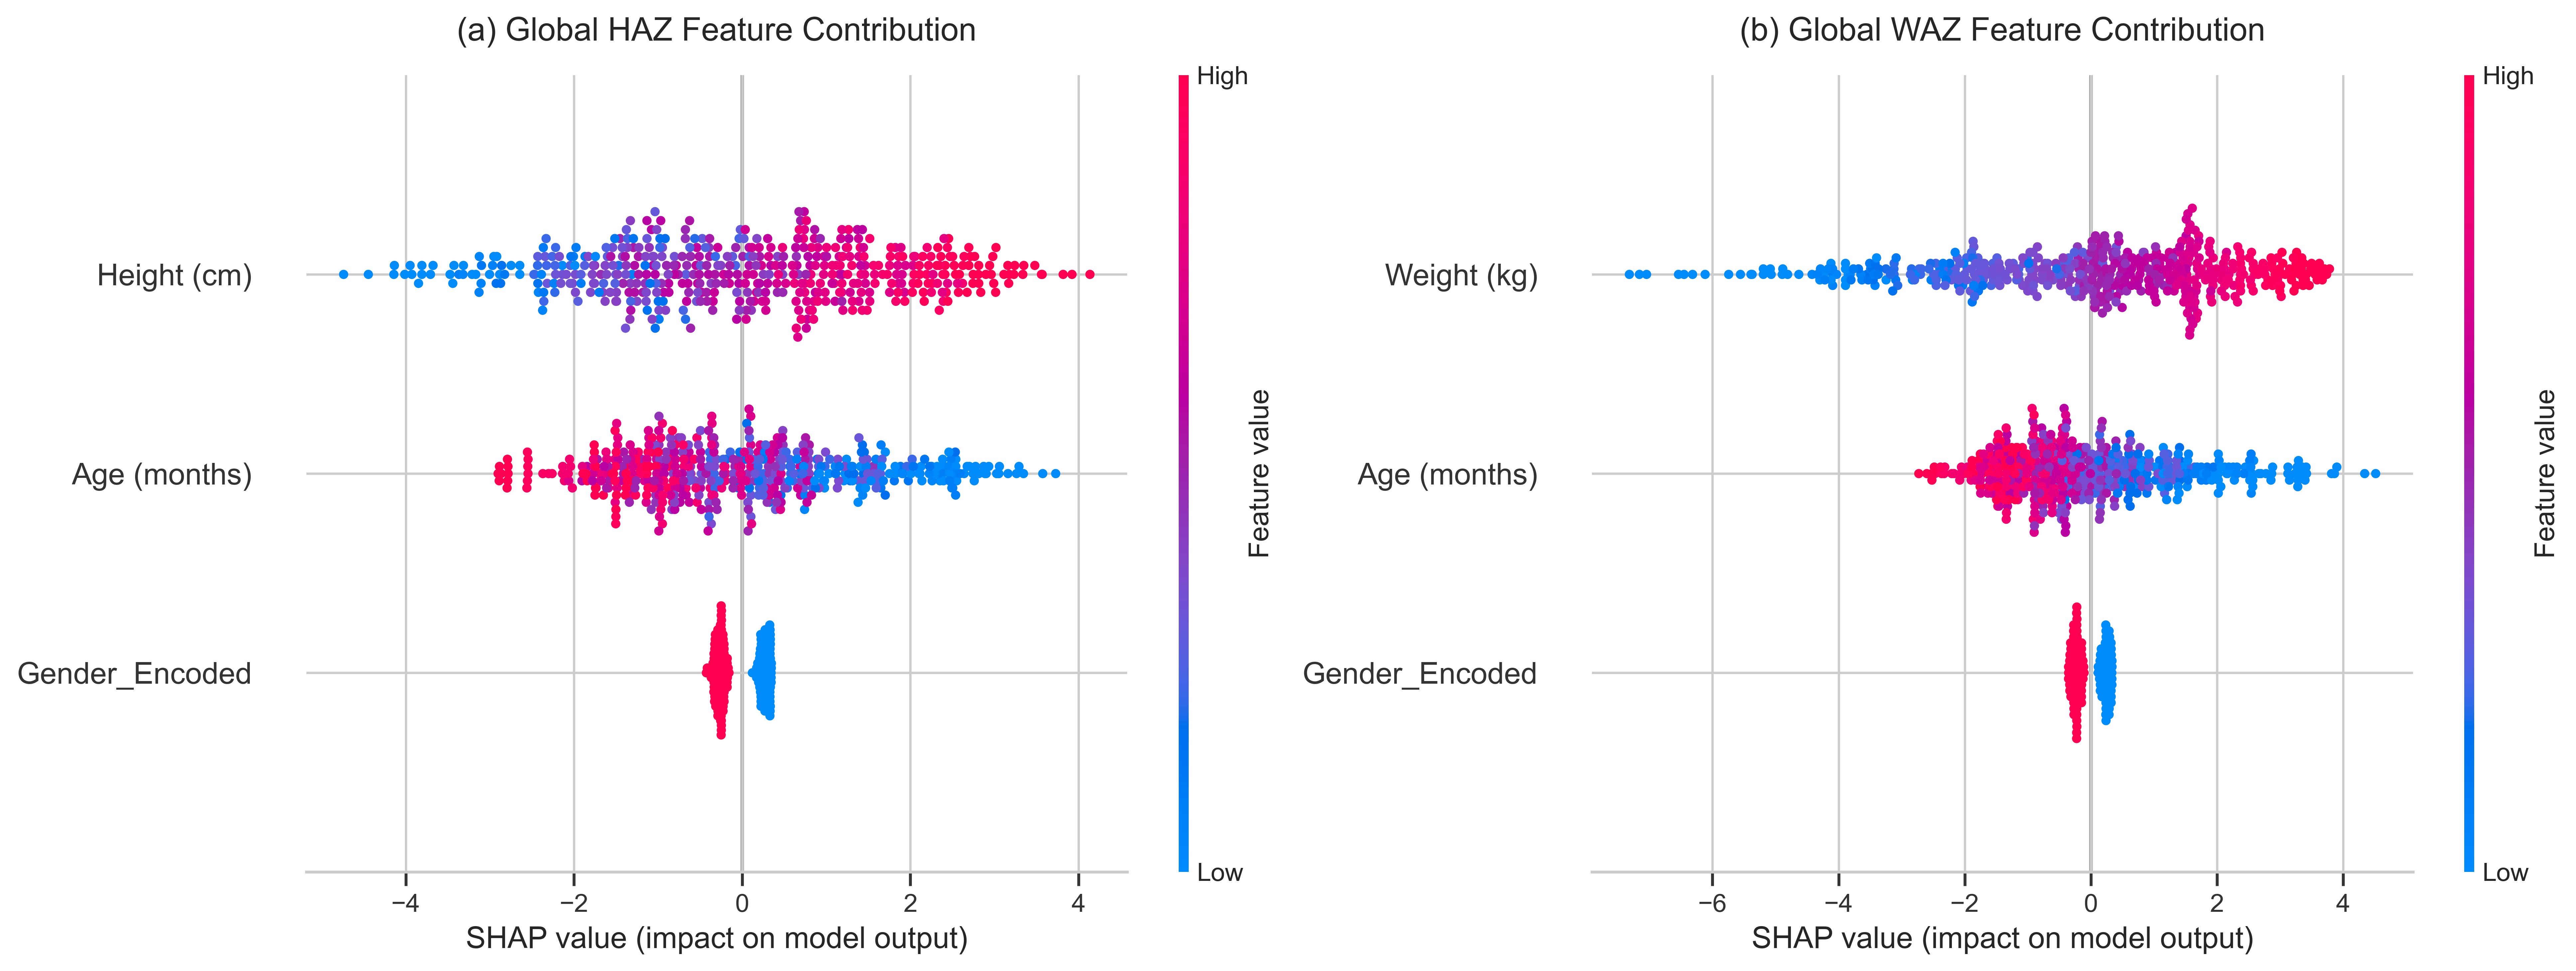

In [5]:
plot_metadata = {}

def save_figure(relative_path):
    path = OUT / relative_path
    fig = plt.gcf()
    fig.tight_layout()
    fig.savefig(path.with_suffix('.png'), dpi=500, bbox_inches='tight')
    fig.savefig(path.with_suffix('.pdf'), dpi=500, bbox_inches='tight')
    with Image.open(path.with_suffix('.png')) as image:
        pixels = list(image.size)
    plot_metadata[str(relative_path)] = {
        'figure_inches': fig.get_size_inches().tolist(), 'png_pixels': pixels,
        'dpi': 500, 'font_family': list(mpl.rcParams['font.family']),
    }
    plt.show()
    plt.close(fig)

np.random.seed(42)
plt.figure(figsize=(10, 6))
shap.summary_plot(explanations['HAZ'], samples['HAZ'], show=False)
plt.title('SHAP Summary Plot for HAZ Regression Model', fontsize=12, pad=15)
save_figure(Path('regression/regression_shap_summary'))

np.random.seed(42)
fig = plt.figure(figsize=(16, 6))
plt.subplot(1, 2, 1)
shap.summary_plot(explanations['HAZ'], samples['HAZ'], show=False, plot_size=None)
plt.title('(a) Global HAZ Feature Contribution', fontsize=14, pad=15)
plt.subplot(1, 2, 2)
shap.summary_plot(explanations['WAZ'], samples['WAZ'], show=False, plot_size=None)
plt.title('(b) Global WAZ Feature Contribution', fontsize=14, pad=15)
save_figure(Path('regression/shap_summary_komparasi'))

## Classification figures

Show the `Stunted` output, as in the original manuscript. Select the first
holdout child predicted as Stunted by Random Forest, using the same selection
rule as the original waterfall. This is an illustration, not a representative
clinical case or evidence of causal effects.

CSV row index: 50074 | observed label: Stunted
RF P(Stunted): 1.0 | baseline: 0.24966072910001744


<ipython-input-1-b26026768461>:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


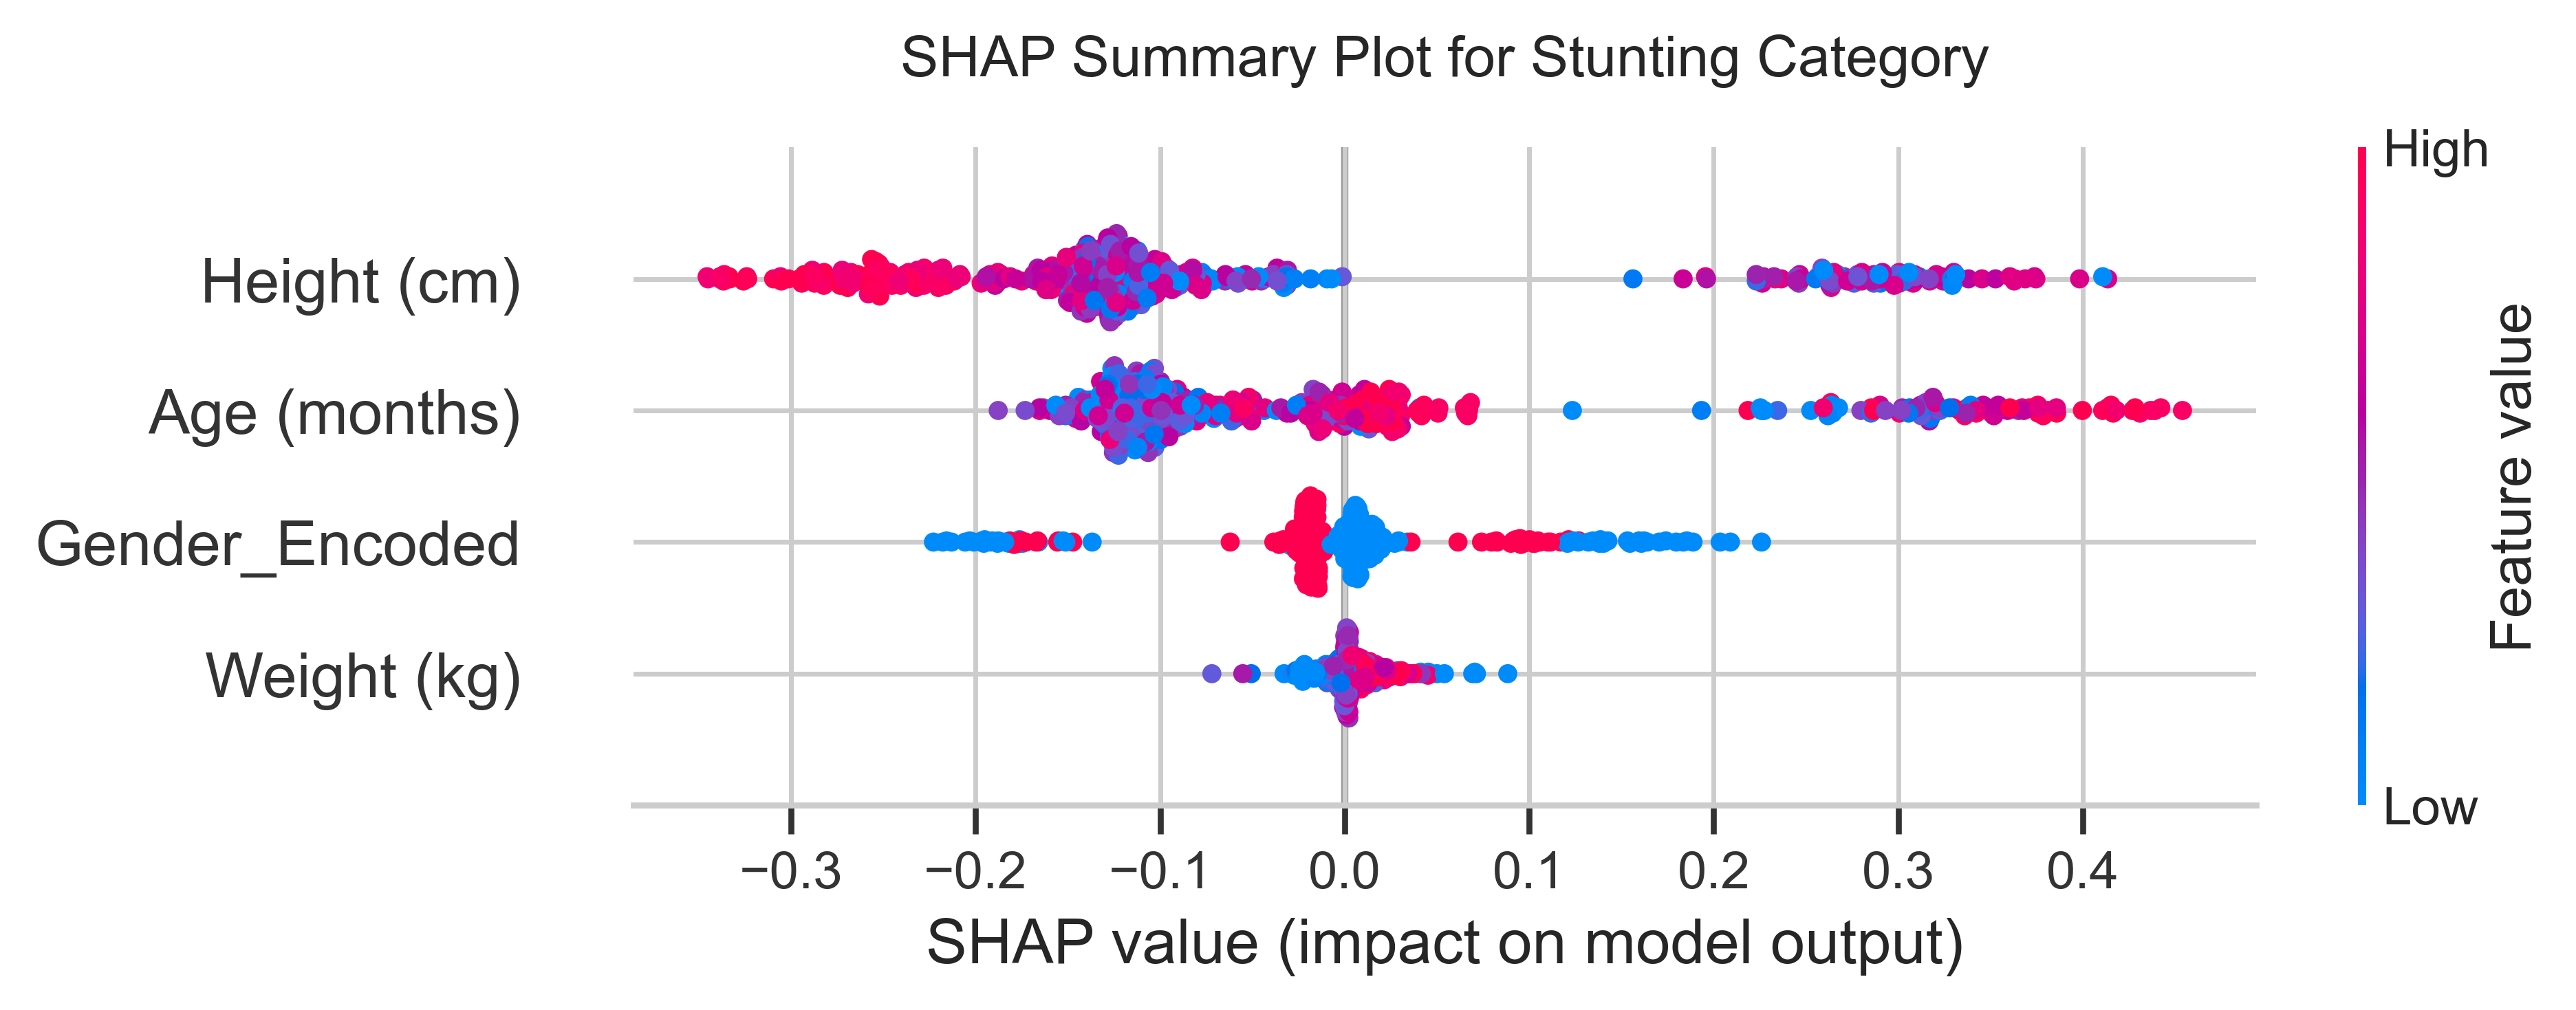

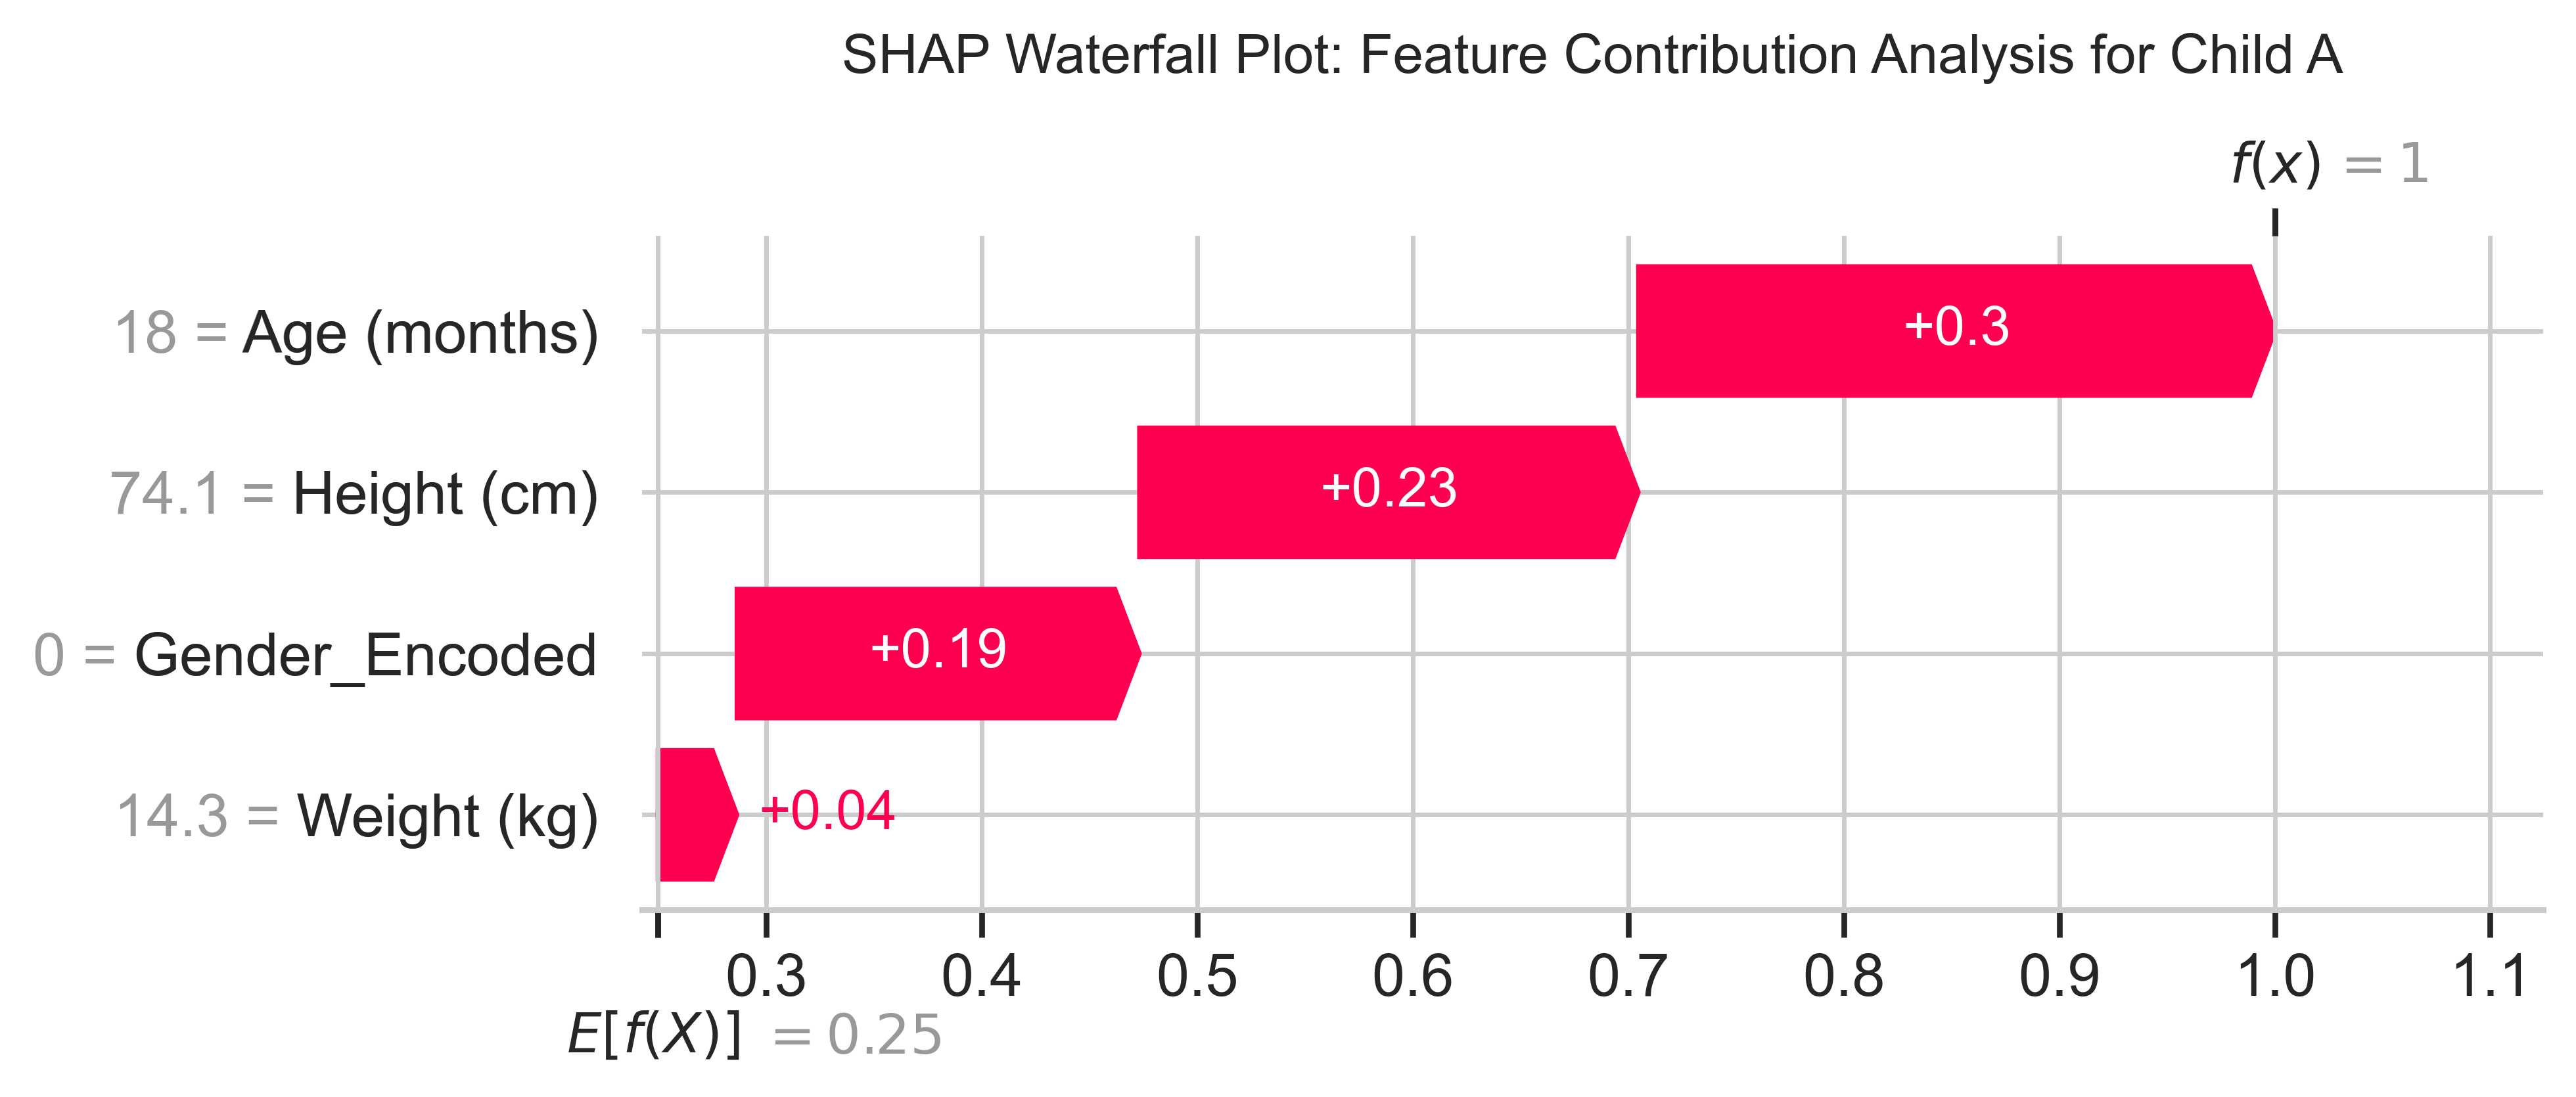

,Feature,Value,SHAP_for_Stunted
0,Gender_Encoded,0.0,0.186779
1,Age (months),18.0,0.295331
2,Height (cm),74.1,0.231549
3,Weight (kg),14.3,0.036680


In [6]:
np.random.seed(42)
plt.figure(figsize=(10, 6))
shap.summary_plot(
    explanations['classification'].values[:, :, stunted_output],
    samples['classification'], show=False,
)
plt.title('SHAP Summary Plot for Stunting Category', fontsize=12, pad=15)
save_figure(Path('classification/classification_shap_summary'))

holdout_X = X['classification'].loc[test_rows]
holdout_predictions = clf.predict(holdout_X)
stunted_positions = np.flatnonzero(holdout_predictions == stunted_code)
assert len(stunted_positions), 'No RF-predicted Stunted case in holdout'
case_row = int(holdout_X.index[stunted_positions[0]])
case_X = holdout_X.loc[[case_row]]
case_shap = explainers['classification'](case_X, approximate=False, check_additivity=True)
case_probabilities = clf.predict_proba(case_X)[0]
case_base = float(case_shap.base_values[0, stunted_output])
case_values = case_shap.values[0, :, stunted_output]
case_probability = float(case_probabilities[stunted_output])
case_reconstruction = case_base + float(case_values.sum())
np.testing.assert_allclose(case_reconstruction, case_probability, rtol=0, atol=1e-7)
case_error = abs(case_reconstruction - case_probability)
case_explanation = shap.Explanation(
    values=case_values, base_values=case_base,
    data=case_X.iloc[0].to_numpy(), feature_names=FEATURES['classification'],
)
plt.figure(figsize=(10, 5))
shap.plots.waterfall(case_explanation, show=False)
plt.title('SHAP Waterfall Plot: Feature Contribution Analysis for Child A', fontsize=12, pad=15)
save_figure(Path('classification/classification_shap_waterfall'))

case_table = pd.DataFrame({
    'Feature': FEATURES['classification'], 'Value': case_X.iloc[0].to_numpy(),
    'SHAP_for_Stunted': case_values,
})
case_table.to_csv(OUT / 'waterfall_case.csv', index=False)
print('CSV row index:', case_row, '| observed label:', df.loc[case_row, 'Stunting'])
print('RF P(Stunted):', case_probability, '| baseline:', case_base)
display(case_table)

## Evidence and scope

Arrays retain every explanation row, input, baseline, contribution and model
output for independent checking. Importance is mean absolute SHAP over the
specified 500-row sample. Classification importance is for Stunted only.
These explanations describe fitted model behaviour on synthetic inputs,
not clinical causality, external validation, or all cross-validation fits.

In [7]:
arrays = {}
for task, explanation in explanations.items():
    arrays[f'{task}_row_index'] = samples[task].index.to_numpy()
    arrays[f'{task}_inputs'] = samples[task].to_numpy()
    arrays[f'{task}_shap'] = explanation.values
    arrays[f'{task}_base'] = explanation.base_values
    arrays[f'{task}_prediction'] = predictions[task]
arrays.update({
    'train_row_index': train_rows, 'test_row_index': test_rows,
    'case_row_index': np.array([case_row]), 'case_inputs': case_X.to_numpy(),
    'case_shap': case_shap.values, 'case_base': case_shap.base_values,
    'case_probabilities': case_probabilities,
})
np.savez_compressed(OUT / 'explanations.npz', **arrays)

summary = {
    'purpose': 'Reviewer 1 Comment 5: SHAP of original selected Random Forest configurations',
    'model_fit': 'Original 80:20 holdout training instances; not CV-fold or grouped revision models',
    'model_selection_basis': 'Primary original five-fold CV comparison, not supplementary grouped CV',
    'split': {'rows': len(df), 'train': len(train_rows), 'test': len(test_rows),
              'test_size': 0.2, 'random_state': 42, 'stratify': None},
    'gender_encoding': {'Female': 0, 'Male': 1},
    'classes': target_encoder.classes_.tolist(), 'stunted_output_index': stunted_output,
    'features': FEATURES,
    'models': {task: {'path': str(MODEL_PATHS[task]), 'sha256': source_hashes[str(MODEL_PATHS[task])],
                     'class': type(model).__name__, 'parameters': model.get_params()}
               for task, model in models.items()},
    'tree_shap': {'feature_perturbation': 'tree_path_dependent', 'approximate': False,
                  'background_data': None, 'classification_scale': 'class probability',
                  'regression_scale': 'predicted Z-score',
                  'baseline': 'Saved tree statistics; classifier baseline includes training class weights'},
    'samples': {'rows_per_task': 500, 'random_state': 42,
                'regression': 'Original full-frame sample; all indices verified in original holdout',
                'classification': 'Original holdout sample',
                'all_samples_in_holdout': True},
    'mean_absolute_shap_ranking': importance.to_dict(orient='records'),
    'waterfall': {'row_index': case_row, 'selection': 'First holdout RF prediction equal to Stunted',
                  'observed_label': str(df.loc[case_row, 'Stunting']), 'predicted_label': 'Stunted',
                  'features': case_X.iloc[0].to_dict(), 'baseline': case_base,
                  'predicted_stunted_probability': case_probability,
                  'sum_of_shap': float(case_values.sum()), 'additivity_error': case_error},
    'plots': plot_metadata,
    'versions': {name: importlib.metadata.version(name) for name in
                 ['numpy', 'pandas', 'scikit-learn', 'shap', 'matplotlib', 'seaborn', 'joblib']},
    'limitations': [
        'Original synthetic data and original fitted targets; no WHO target revision in this analysis',
        'One retained holdout-trained RF instance per task, not explanations pooled across CV folds',
        'Classification figures explain Stunted only',
        'SHAP contributions are model associations, not clinical or causal effects',
    ],
}
(OUT / 'summary.json').write_text(json.dumps(summary, indent=2) + '\n')
unchanged = {path: sha256(path) == expected for path, expected in source_hashes.items()}
assert all(unchanged.values()), 'An original input/model/notebook/image changed during execution'
verification = {
    'original_sources_sha256': source_hashes, 'original_sources_unchanged': unchanged,
    'max_additivity_error': max_errors, 'additivity_tolerance': 1e-7,
    'waterfall_additivity_error': case_error, 'all_samples_in_holdout': True,
    'classifier_bootstrap_root_max_error': max(root_errors),
    'elapsed_shap_seconds': elapsed,
    'output_sha256': {str(path.relative_to(OUT)): sha256(path)
                      for path in sorted(OUT.rglob('*')) if path.is_file()
                      and path.name not in ['verification.json', 'CATATAN_HASIL.md']},
}
(OUT / 'verification.json').write_text(json.dumps(verification, indent=2) + '\n')
print('Verified: feature order, original split, held-out samples, all-class additivity, source integrity.')
print('No model fitting or primary metric changes were performed.')
print('Saved evidence and PNG/PDF figures to', OUT.relative_to(ROOT))

Verified: feature order, original split, held-out samples, all-class additivity, source integrity.
No model fitting or primary metric changes were performed.
Saved evidence and PNG/PDF figures to results/shap_revised
